E-COMMERCE ANALYSIS: UCI Online Retail Dataset

Goal: clean a messy real-world sales dataset, compute `Revenue`, and find the top 10 countries by total revenue.

Dataset: UCI Online Retail (https://archive.ics.uci.edu/dataset/352/online+retail), also on Kaggle as `Online Retail.csv`. Put the file in the same folder as this notebook.

IMPORTING THE DEPENDENCIES

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

LOADING THE DATASET

In [39]:

# unicode_escape is needed because the file has some non-UTF8 characters
FILE_PATH = 'Online Retail.xlsx'
full_df = pd.read_excel(FILE_PATH)

In [14]:
#Checking the number of rows and columns in the full dataset
full_df.shape

(541909, 8)

SAMPLING 10% OF THE DATA

In [15]:
SAMPLE_FRACTION = 0.1

# random_state keeps the sample the same every time we run it
df = full_df.sample(frac=SAMPLE_FRACTION, random_state=42).reset_index(drop=True)
df.shape

(54191, 8)

INITIAL DATA INSPECTION

In [16]:
#Print the first 5 rows of the dataframe
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315.0,United Kingdom
1,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031.0,United Kingdom
2,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031.0,United Kingdom
3,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198.0,United Kingdom
4,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502.0,United Kingdom


In [17]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
54186,581433,22960,JAM MAKING SET WITH JARS,6,2011-12-08 15:54:00,4.25,14911.0,EIRE
54187,551993,85132C,CHARLIE AND LOLA FIGURES TINS,4,2011-05-05 15:39:00,1.95,14697.0,United Kingdom
54188,C559253,22326,ROUND SNACK BOXES SET OF4 WOODLAND,-1,2011-07-07 11:44:00,2.95,12472.0,Germany
54189,559491,21078,SET/20 STRAWBERRY PAPER NAPKINS,1,2011-07-08 13:53:00,2.46,NaN,United Kingdom
54190,548992,21452,TOADSTOOL MONEY BOX,12,2011-04-05 13:52:00,2.95,13089.0,United Kingdom


In [18]:
#Data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54191 entries, 0 to 54190
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    54191 non-null  object        
 1   StockCode    54191 non-null  object        
 2   Description  54042 non-null  object        
 3   Quantity     54191 non-null  int64         
 4   InvoiceDate  54191 non-null  datetime64[ns]
 5   UnitPrice    54191 non-null  float64       
 6   CustomerID   40551 non-null  float64       
 7   Country      54191 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 3.3+ MB


In [19]:
#Check for missing values
df.isnull().sum()

InvoiceNo          0
StockCode          0
Description      149
Quantity           0
InvoiceDate        0
UnitPrice          0
CustomerID     13640
Country            0
dtype: int64

In [20]:
#Percentage of missing values in each column
(df.isnull().sum() / len(df) * 100).round(2)

InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     25.17
Country         0.00
dtype: float64

STATISTICAL MEASURES

In [21]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,54191.000000,54191,54191.000000,40551.000000
mean,10.638962,2011-07-04 03:02:48.858297600,4.667784,15279.710167
min,-2472.000000,2010-12-01 08:26:00,0.000000,12346.000000
25%,1.000000,2011-03-28 11:35:00,1.250000,13950.500000
50%,3.000000,2011-07-19 11:03:00,2.080000,15122.000000
75%,10.000000,2011-10-18 17:05:00,4.130000,16791.000000
max,74215.000000,2011-12-09 12:50:00,13541.330000,18287.000000
std,321.689757,NaN,88.434068,1715.070628


What to look for here:
- `Quantity` has negative values (returns / cancellations)
- `UnitPrice` has zero (or negative) values (free items / adjustments / errors)

In [22]:
#Cancelled invoices start with 'C'. Checking they match the negative quantities
cancelled = df[df['InvoiceNo'].astype(str).str.startswith('C')]
print("Cancelled invoices :", len(cancelled))
print("Negative quantity rows :", (df['Quantity'] < 0).sum())
cancelled['Quantity'].describe()

Cancelled invoices : 945
Negative quantity rows : 1074


count     945.000000
mean      -10.713228
std        56.795773
min     -1350.000000
25%        -6.000000
50%        -2.000000
75%        -1.000000
max        -1.000000
Name: Quantity, dtype: float64

In [23]:
#Zero price rows (free items or errors)
df[df['UnitPrice'] <= 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
81,574257,72818,NaN,-3,2011-11-03 13:46:00,0.0,NaN,United Kingdom
160,576673,22548,adjustment,4,2011-11-16 11:59:00,0.0,NaN,United Kingdom
669,547337,85025C,barcode problem,-230,2011-03-22 11:47:00,0.0,NaN,United Kingdom
732,578374,21937,found,50,2011-11-24 11:21:00,0.0,NaN,United Kingdom
814,539749,22734,NaN,30,2010-12-21 15:33:00,0.0,NaN,United Kingdom


HANDLING MISSING VALUES

Missing `Description`: the row doesn't tell us what was sold, so we drop it (very small share of the data).

Missing `CustomerID`: a big chunk of the data (guest checkouts). We keep these rows because we only need revenue and country right now. CustomerID is only needed for customer-level analysis.

In [24]:
#Drop rows where Description is missing
df = df.dropna(subset=['Description'])
df['Description'].isnull().sum()

np.int64(0)

In [25]:
#CustomerID is intentionally kept, just checking how many are missing
df['CustomerID'].isnull().sum()

np.int64(13491)

FIXING DATA TYPES

In [26]:
#Convert InvoiceDate from object (string) to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['InvoiceDate'].dtype

dtype('<M8[ns]')

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 54042 entries, 0 to 54190
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    54042 non-null  object        
 1   StockCode    54042 non-null  object        
 2   Description  54042 non-null  object        
 3   Quantity     54042 non-null  int64         
 4   InvoiceDate  54042 non-null  datetime64[ns]
 5   UnitPrice    54042 non-null  float64       
 6   CustomerID   40551 non-null  float64       
 7   Country      54042 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 3.7+ MB


REMOVING DUPLICATES

In [28]:
#Rows that are identical in every column
num_duplicates = df.duplicated().sum()
print(f"Found {num_duplicates} fully duplicated rows.")

Found 62 fully duplicated rows.


In [29]:
df = df.drop_duplicates()
print(f"Dataframe size after removing duplicates: {len(df)} rows.")

Dataframe size after removing duplicates: 53980 rows.


FILTERING OUT RETURNS AND FREE ITEMS

In [30]:
#Keep only sales (Quantity > 0), this removes returns and cancellations
df = df[df['Quantity'] > 0]

#Keep only rows with a real price (UnitPrice > 0), this removes free items and errors
df = df[df['UnitPrice'] > 0]

print(f"Dataframe size after filtering: {len(df)} rows.")

Dataframe size after filtering: 52933 rows.


In [31]:
#Quick check, both should now be positive
print(df['Quantity'].min(), df['UnitPrice'].min())

1 0.001


CLEANING TEXT COLUMNS

In [32]:
#Remove leading/trailing spaces
df['Description'] = df['Description'].str.strip()
df['Country'] = df['Country'].str.strip()

In [33]:
#EIRE is how this dataset names Ireland
df['Country'] = df['Country'].replace('EIRE', 'Ireland')
df['Country'].unique()

array(['United Kingdom', 'Australia', 'Norway', 'Finland', 'Germany',
       'Bahrain', 'Ireland', 'Spain', 'France', 'Canada', 'RSA',
       'Netherlands', 'Italy', 'Austria', 'Channel Islands',
       'Unspecified', 'Sweden', 'Belgium', 'Portugal', 'Cyprus', 'Poland',
       'Switzerland', 'USA', 'Japan', 'Denmark', 'Hong Kong', 'Iceland',
       'Singapore', 'Israel', 'United Arab Emirates', 'Greece',
       'Lithuania', 'European Community', 'Malta', 'Saudi Arabia',
       'Lebanon', 'Brazil', 'Czech Republic'], dtype=object)

CREATING THE REVENUE COLUMN

In [34]:
#Revenue = Quantity x UnitPrice
df['Revenue'] = df['Quantity'] * df['UnitPrice']
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315.0,United Kingdom,20.40
1,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031.0,United Kingdom,27.80
2,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031.0,United Kingdom,2.60
3,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198.0,United Kingdom,5.85
4,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502.0,United Kingdom,19.90


In [35]:
df['Revenue'].describe()

count    52933.000000
mean        20.713439
std        346.647569
min          0.001000
25%          3.750000
50%          9.900000
75%         17.700000
max      77183.600000
Name: Revenue, dtype: float64

TOP 10 COUNTRIES BY TOTAL REVENUE

In [36]:
#Group by Country, sum Revenue, sort high to low, take top 10
top_countries = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10)
print("--- Top 10 Countries by Revenue (GBP) ---")
print(top_countries)

--- Top 10 Countries by Revenue (GBP) ---
Country
United Kingdom    941268.661
Netherlands        27435.830
Ireland            26066.000
France             23645.330
Germany            22389.510
Australia          12429.990
Spain               5600.900
Switzerland         5483.890
Hong Kong           3597.850
Belgium             3593.510
Name: Revenue, dtype: float64


PLOTTING THE RESULT

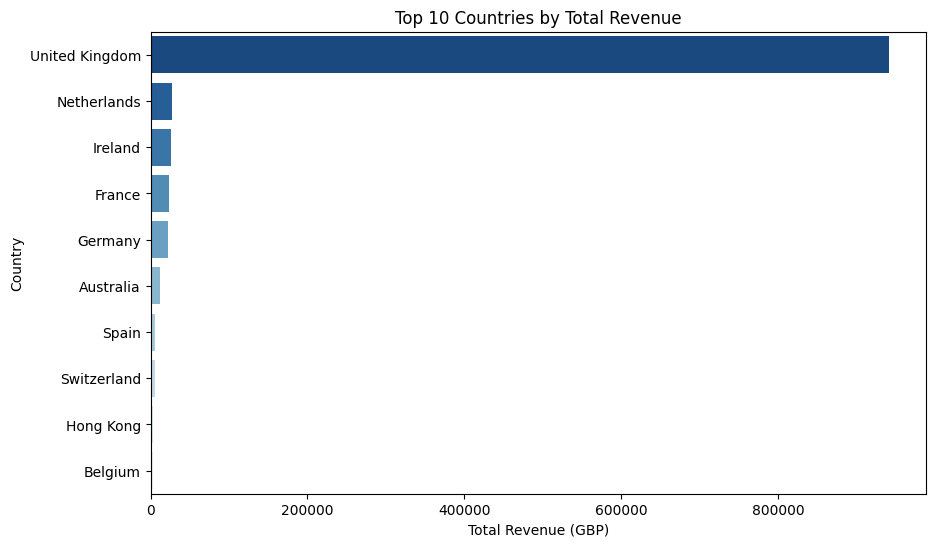

In [37]:
plt.figure(figsize=(10,6))

sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index, palette='Blues_r', legend=False)

plt.title("Top 10 Countries by Total Revenue")
plt.xlabel("Total Revenue (GBP)")
plt.ylabel("Country")

plt.show()

The UK dominates because the store is UK-based, so the other bars look tiny next to it. Here is the same chart without the UK, to compare the international markets.

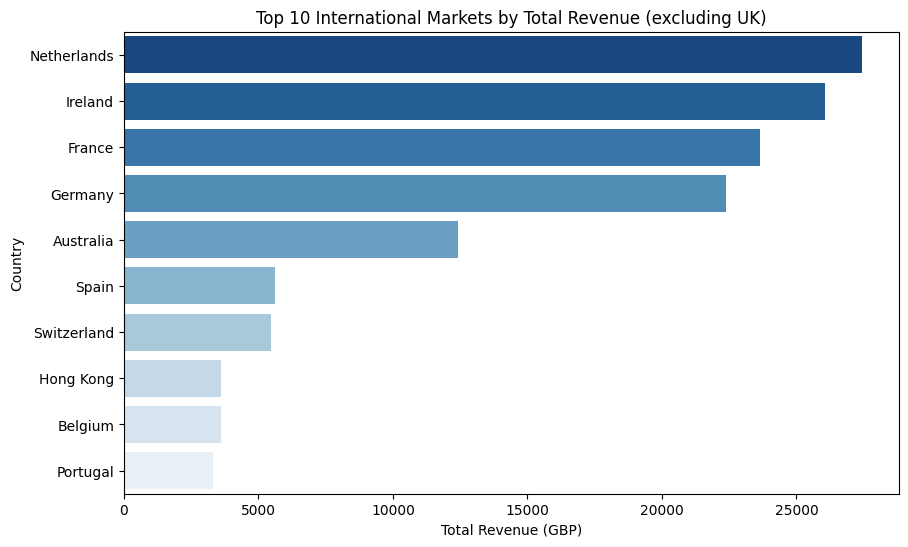

In [38]:
#Same plot without the UK
plt.figure(figsize=(10,6))

international = df[df['Country'] != 'United Kingdom'].groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10)

sns.barplot(x=international.values, y=international.index, hue=international.index, palette='Blues_r', legend=False)

plt.title("Top 10 International Markets by Total Revenue (excluding UK)")
plt.xlabel("Total Revenue (GBP)")
plt.ylabel("Country")

plt.show()

## Business Insights

- The United Kingdom generates the highest revenue,
  which is expected because the store is UK-based.
- International countries contribute additional revenue,
  with the highest-performing international markets
  identified through the country-level analysis.
- The international comparison chart provides a clearer
  view of revenue distribution outside the UK.

## Limitations

- Only 10% of the original dataset was analyzed.
- Revenue figures are estimates based on a random sample.
- Returns and free items were excluded from the analysis.

CONCLUSION

- Sampled 10% of the data, removed missing descriptions and duplicates, converted `InvoiceDate` to datetime
- Filtered out returns (negative quantity) and free items (zero price)
- Created the `Revenue` column and found the top 10 countries by total revenue

Note: the sample is random, so the exact numbers are an estimate of the full data, not the full-data totals.